## Time to get your hands dirty.  The transient Universe
### Tasks

**Remember this is a real research example, not an exam! You're welcome (and encouraged actually!) to use all the tutorials/answers/hack you find online!**


1) Read in `solutions/transient.npy`. This is a (100 x 3) numpy array, containing some time-series measurements from a transient phenomenon. The first column is time (arbitrary units), the second column is the flux (arbitrary units), and the third column are homoescedastic measurement uncertainties on the flux. Plot this data with the uncertainties.

2) One possible model for this data is a sharp burst with an exponential tail rising above a nominal background level. This model can be described as:

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

where $b$ is the background amplitude, $A$ is the burst amplitude, $t_0$ is the burst epoch, and $\alpha$ encodes how rapidly the burst dies off.

Code this burst model, and code a likelihood function for this data with the burst model. *Hint: This is similar in spirit to the likelihood when fitting polynomials to data, except now $x$ is time, and the polynomial model is now the burst model.* 

3) Using one of the MCMC sampler that we looked at in class (`emcee`, `pymc`), perform a Bayesian analysis that recovers an MCMC chain of posterior probability samples for the joint parameter space of $\{b,A,t_0,\alpha\}$. You must decide on how many samples are appropriate for running your MCMC. For your priors, make them $b\in \mathrm{Uniform}[0,50]$, $A\in \mathrm{Uniform}[0,50]$, $t_0\in \mathrm{Uniform}[0,100]$, and $\ln\alpha\in \mathrm{Uniform}[-5,5]$ (careful: uniform in $\ln\alpha$, not $\alpha$).

4) Perform an appropriate check to burn-in your chain, and thin the chain by selecting only points every auto-correlation length. If you are left with a small number of samples after thinning then you may need to run your MCMC for longer in (3).

5) Make a corner plot of the $4$-D parameter space, with labels, $[68,95]\%$ credible levels and quantiles, and titles.

6) Now choose $100$ samples randomly from your burned, thinned chain and plot the $100$ corresponding burst time-series on a figure along with the original data. You may want to choose a transparency for these $100$ burst curves that allows you to see everything nicely. These are showing the posterior spread of model solutions that are consistent with the data.

7) For each parameter, find the median and 90% credible region of the marginalized distribution and quote results as, for instance, $t_0=X^{+Y}_{-Z}$ 



In [21]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import warnings; warnings.simplefilter('ignore')
import corner
from IPython.display import display, Math

In [2]:
#################################################################################################
# Data Loading
#################################################################################################
data = np.load('transient.npy')

time = data[:, 0]
flux = data[:, 1]
uncertainties = data[:, 2]

#### Data plotting

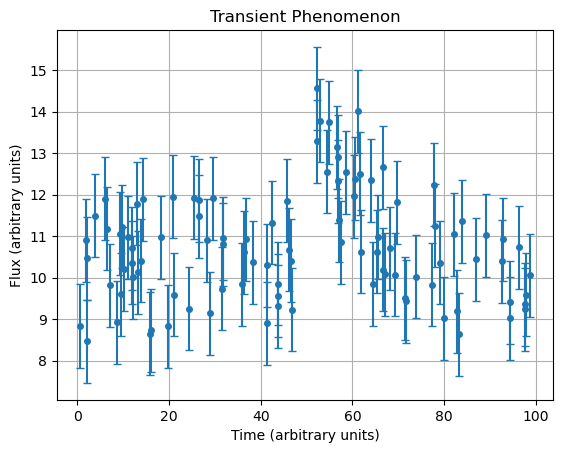

In [3]:
plt.errorbar(time, flux, yerr=uncertainties, fmt='o', markersize=4, capsize=3)
plt.xlabel('Time (arbitrary units)')
plt.ylabel('Flux (arbitrary units)')
plt.title('Transient Phenomenon')
plt.grid(True)
plt.show()

I define the model we're going to use

In [4]:
def model(x, data): 
    b = x[0]
    A = x[1]
    t0 = x[2]
    lna = x[3]

    a = np.exp(lna)

    if data.ndim > 1:
        t = data[: , 0]
    else: t = data

    y = np.full_like(t, b)
    
    mask = t > t0
    y[mask] = b + A * np.exp(-a * (t[mask] - t0))
    
    return y

I define the Likelihood.
For the priors $b\in \mathrm{Uniform}[0,50]$, $A\in \mathrm{Uniform}[0,50]$, $t_0\in \mathrm{Uniform}[0,100]$, and $\ln\alpha\in \mathrm{Uniform}[-5,5]$ 

In [5]:
def log_Likelihood(x, data):
    # Gaussian likelihood 
    return np.sum(-(data[:, 1] - model(x, data))**2 /(2 *data[:, 2]**2))

def log_Prior(x):
    
    if not (0 < x[0] < 50 and 0 < x[1] < 50 and 0 < x[2] < 100 and -5 < x[3] < 5):
        return -np.inf
    return 0.0
            
    return prior_a

def myLogPosterior(x, data):
    return log_Likelihood(x, data) + log_Prior(x)


### Emcee 
**OSS:** intead of computing $\alpha$ I'm using directly $\ln(\alpha)$. Running the code, I found out a better convergence with this choiche. I suppose it is due to the fact that the $\ln(\alpha)$ space is easier to investigate for the walkers, instead of the $\alpha$ space. 

In [6]:
ndim = 4  
nwalkers = 30  
burn = 10000  
nsteps = 100000   

intervals = np.array([[9, 11], [0,20], [45, 55], [-3,-1]])

starting_guess = np.zeros((nwalkers, ndim))

starting_guess[:,0] = np.random.uniform(low = intervals[0,0], high = intervals[0,1], size = nwalkers)
starting_guess[:,1] = np.random.uniform(low = intervals[1,0], high = intervals[1,1], size = nwalkers)
starting_guess[:,2] = np.random.uniform(low = intervals[2,0], high = intervals[2,1], size = nwalkers)
starting_guess[:,3] = np.random.uniform(low = intervals[3,0], high = intervals[3,1], size = nwalkers)

sampler = emcee.EnsembleSampler(nwalkers, ndim, myLogPosterior, args=[data])
sampler.run_mcmc(starting_guess, nsteps, progress=False); 

State([[10.12777219  4.38091825 50.20964148 -2.36440963]
 [10.32017935  4.38324152 49.73663564 -2.407513  ]
 [10.3067942   4.11650112 51.99151378 -1.94025913]
 [10.26289075  3.24747812 51.54786449 -2.27816701]
 [10.47627147  5.83078151 48.35804952 -2.18166402]
 [10.3410719   3.85877766 51.70078277 -2.14169929]
 [10.31528361  6.68671857 47.84231474 -1.95045253]
 [10.37169145  8.81997739 46.95788435 -1.86102449]
 [10.24851258  4.96337296 48.8469785  -2.14338501]
 [10.22859026  3.42282155 51.77579477 -2.3736527 ]
 [10.46147371  6.65819585 47.02443206 -2.02034385]
 [10.14908805  5.35296161 47.80546989 -2.36352058]
 [10.20368568  4.97577102 51.93486435 -1.74630183]
 [10.15133777  6.39517181 48.43869124 -2.07445201]
 [10.24578475  5.22920932 48.79412647 -2.14104365]
 [10.21965092  5.99862711 49.76194339 -2.01605956]
 [10.28639969  4.39728917 49.62803061 -2.24621572]
 [10.26966079  6.01901405 48.45352659 -2.17746716]
 [10.36118563  5.92726684 48.73647881 -2.00053649]
 [10.29382441  6.6696084 

### Looking at Trace Plots


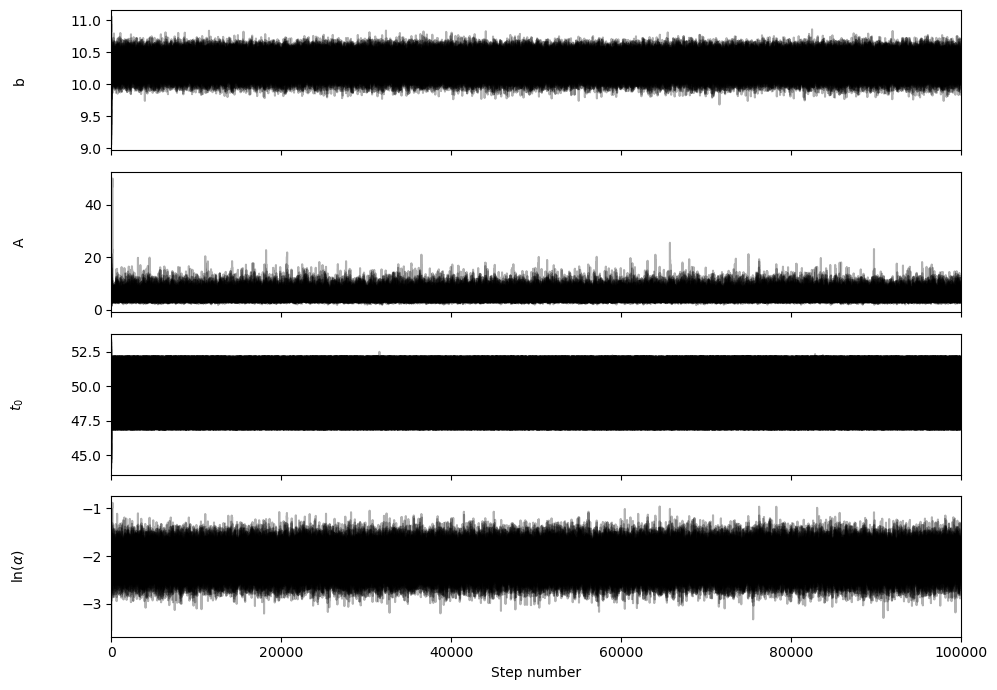

In [7]:
samples = sampler.get_chain()
labels = ["b", "A", r"$t_0$", r"ln$(\alpha)$"]
ndim = len(labels)

fig, axes = plt.subplots(ndim, figsize=(10, 7), sharex=True)

for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    if labels[i] == "a":
        ax.set_yscale('log')
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("Step number");
plt.tight_layout()
plt.show()

In [9]:
tau = sampler.get_autocorr_time()

print(f"Tau (post burn-in): {tau}")
print(f"Max tau: {np.max(tau):.2f}") 

Tau (post burn-in): [59.13615739 85.29708859 78.54672688 63.3909997 ]
Max tau: 85.30


In [10]:
thin = int(np.max(tau+1))
flat_samples = sampler.get_chain(discard=burn, thin=thin, flat=True)

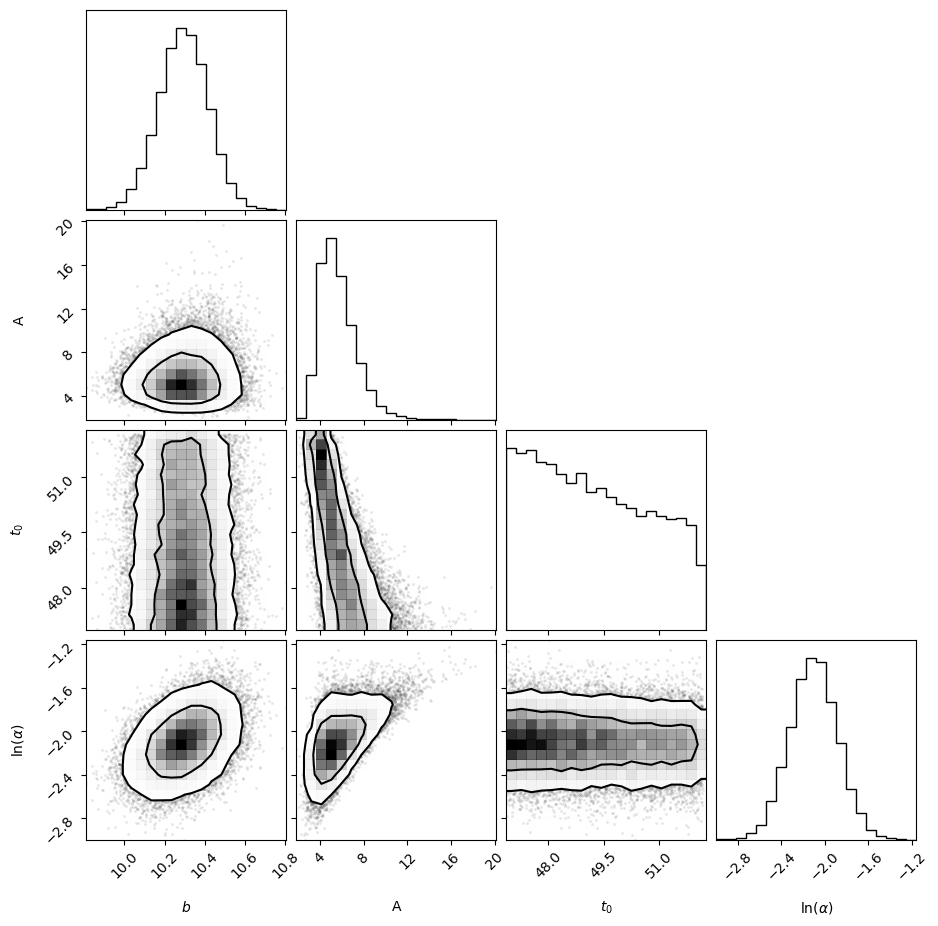

In [11]:
labels = [r"$b$", "A", r"$t_0$", r"ln$(\alpha)$"]
fig = corner.corner(
    flat_samples, labels=labels, levels=[0.68,0.95]
);

##### Plotting 100 Models on the Data

In [12]:
samples = flat_samples[np.random.choice(len(flat_samples), size = 100)]

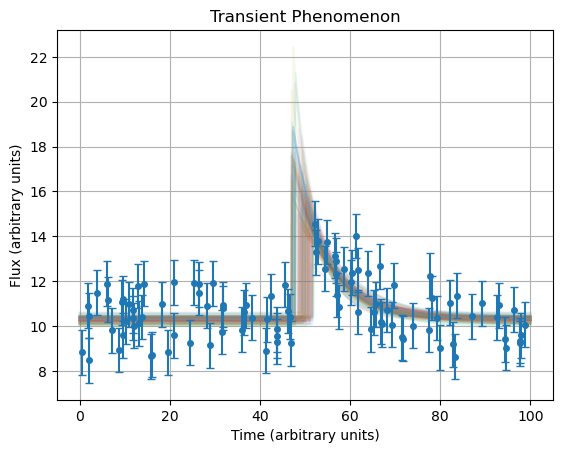

In [13]:
x_grid = np.linspace(0,100,int(1e3))
models = np.array([model(samples[i, :], x_grid) for i in range(len(samples))])

plt.plot(x_grid, models.T, alpha = 0.1)
plt.errorbar(time, flux, yerr=uncertainties, fmt='o', markersize=4, capsize=3)
plt.xlabel('Time (arbitrary units)')
plt.ylabel('Flux (arbitrary units)')
plt.title('Transient Phenomenon')
plt.grid(True)
plt.show()

##### Plotting Marginal Probabilities

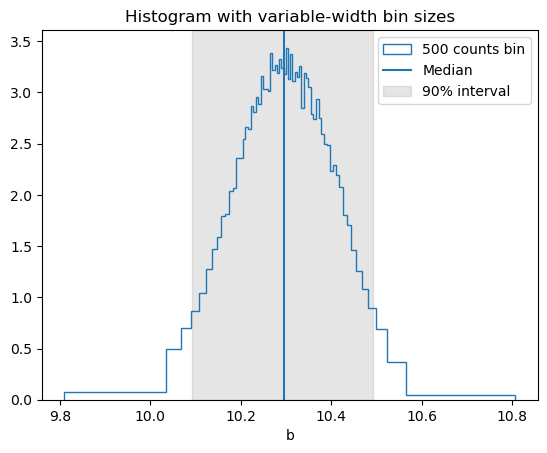

In [14]:
bins500 = np.append(np.sort(flat_samples[:,0])[::500], np.max(flat_samples[:,0])) 
plt.hist(flat_samples[:,0], bins=bins500, density=True, histtype="step", label = "500 counts bin")
plt.axvline(np.median(flat_samples[:,0]), color = 'C0', label = "Median")
b5, b95 = np.percentile(flat_samples[:, 0], [5,95])
plt.axvspan(b5, b95, alpha=0.2, color='gray', label='90% interval')
plt.xlabel(r"b")
plt.title("Histogram with variable-width bin sizes")
plt.legend()
plt.show()

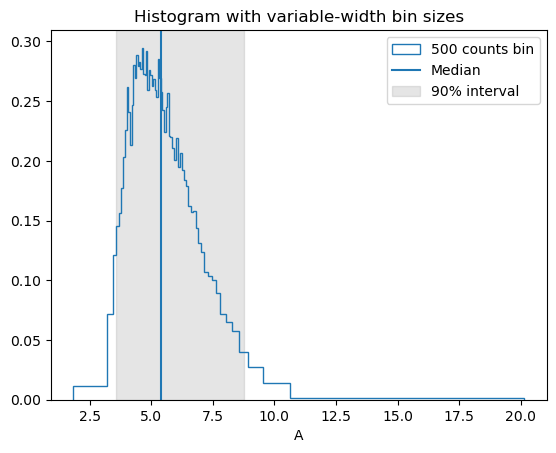

In [15]:
bins500 = np.append(np.sort(flat_samples[:,1])[::500], np.max(flat_samples[:,1])) 
plt.hist(flat_samples[:,1], bins=bins500, density=True, histtype="step", label = "500 counts bin") 
plt.axvline(np.median(flat_samples[:,1]), color = 'C0', label = "Median")
A5, A95 = np.percentile(flat_samples[:, 1], [5,95])
plt.axvspan(A5, A95, alpha=0.2, color='gray', label='90% interval')
plt.xlabel(r"A")
plt.title("Histogram with variable-width bin sizes")
plt.legend()
plt.show()

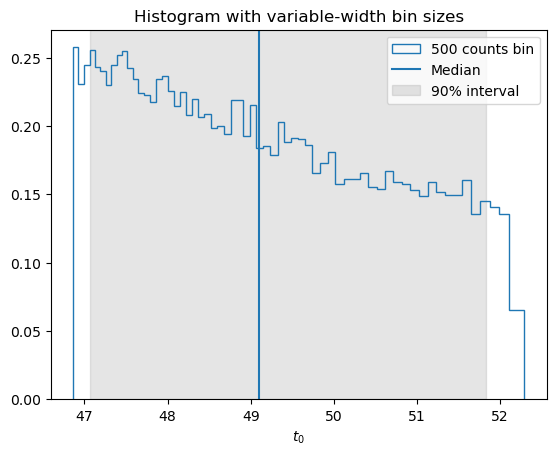

In [16]:
bins500 = np.append(np.sort(flat_samples[:,2])[::500], np.max(flat_samples[:,2])) 
plt.hist(flat_samples[:,2], bins=bins500, density=True, histtype="step", label = "500 counts bin")
plt.axvline(np.median(flat_samples[:,2]), color = 'C0', label = "Median")
t05, t095 = np.percentile(flat_samples[:, 2], [5,95])
plt.axvspan(t05, t095, alpha=0.2, color='gray', label='90% interval')
plt.xlabel(r"$t_0$")
plt.title("Histogram with variable-width bin sizes")
plt.legend()
plt.show()

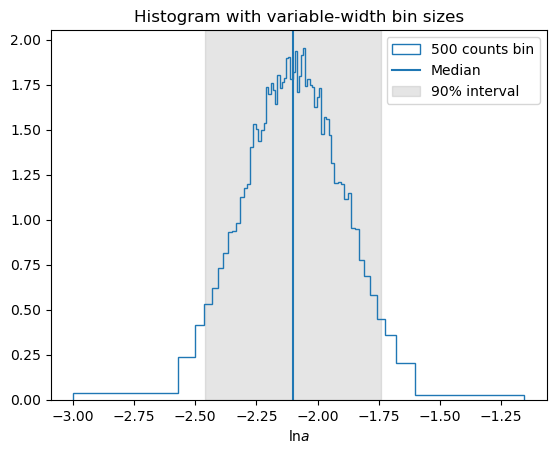

In [17]:
bins500 = np.append(np.sort(flat_samples[:,3])[::500], np.max(flat_samples[:,3])) 
plt.hist(flat_samples[:,3], bins=bins500, density=True, histtype="step", label = "500 counts bin")
plt.axvline(np.median(flat_samples[:,3]), color = 'C0', label = "Median")
a5, a95 = np.percentile(flat_samples[:, 3], [5,95])
plt.axvspan(a5, a95, alpha=0.2, color='gray', label='90% interval')
plt.xlabel(r"ln$a$")
plt.title("Histogram with variable-width bin sizes")
plt.legend()
plt.show()

#### Results

In [32]:
median = [np.median(flat_samples[:,i]) for i in range(4)]
lower = [median[i] - np.percentile(flat_samples[:,i], [5]) for i in range(4)]
upper = [np.percentile(flat_samples[:,i], [95]) - median[i] for i in range(4)]
label = ["b", "A", "t_0", r"\ln(\alpha)"]

for i in range(4):
    latex_str = rf'\text{{The result for }}{label[i]}\text{{ is: }} {label[i]} = {median[i].item():.3f}^{{+{upper[i].item():.3f}}}_{{-{lower[i].item():.3f}}}'
    display(Math(latex_str))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>